<a href="https://colab.research.google.com/github/nkordylewicz/ML-for-space-applications/blob/main/Lab2_ML_Basic_opt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 Solution

In [1]:
!pip install -q pystac-client planetary-computer odc-stac

In [2]:
import numpy as np
import matplotlib.pyplot as mp
import pystac_client, planetary_computer, odc.stac
from shapely.geometry import shape, box

# Data are accessed through Microsoft Planetary Computer
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace)

# Study areas (lon_min, lat_min, lon_max, lat_max)
regions = {"Urban – Kraków centre":         [19.90, 50.04, 19.98, 50.08],
           "Natural – Niepołomice Forest":  [20.33, 50.005, 20.41, 50.045]}
full_bbox = [19.90, 50.00, 20.41, 50.08]

def pick_item(collection, date_range, bbox=full_bbox, extra_query=None, sort_key=None):
    """Return one STAC item that fully covers the given bbox."""
    items = catalog.search(collections=[collection], bbox=bbox,
                           datetime=date_range, query=extra_query).item_collection()
    items = [it for it in items if shape(it.geometry).contains(box(*bbox))]
    if not items:
        raise ValueError(f"No {collection} scene fully covers {bbox} – try per-region search")
    if sort_key: items.sort(key=sort_key)
    return items[0]

# 1. Probability Distribution Function (PDF) of Sentinel data

## 1.1 Access at least three bands of data of Sentinel 2 of natural and urban areas

For this exercise, 4 Sentinel-2 bands were chosen: B02 (blue), B03 (green), B04 (red) and B08 (NIR). Kraków was chosen as urban area, and Niepołomice Forest as natural area.

In [3]:
s2_item = pick_item("sentinel-2-l2a", "2026-05-01/2026-09-30",
                    extra_query={"eo:cloud_cover": {"lt": 5}},
                    sort_key=lambda it: it.properties["eo:cloud_cover"])
print(s2_item.id, s2_item.properties["eo:cloud_cover"], "% clouds")

S2_BANDS = ["B02", "B03", "B04", "B08"]
s2 = {}
for name, bb in regions.items():
    ds = odc.stac.load([s2_item], bands=S2_BANDS, bbox=bb, resolution=10).isel(time=0)
    s2[name] = {b: np.where(ds[b].values > 0, (ds[b].values.astype(float) - 1000) / 10000, np.nan)
                for b in S2_BANDS}

S2B_MSIL2A_20260503T094029_R036_T34UDA_20260503T115712 0.000514 % clouds


## 1.2 Draw the histogram of the images

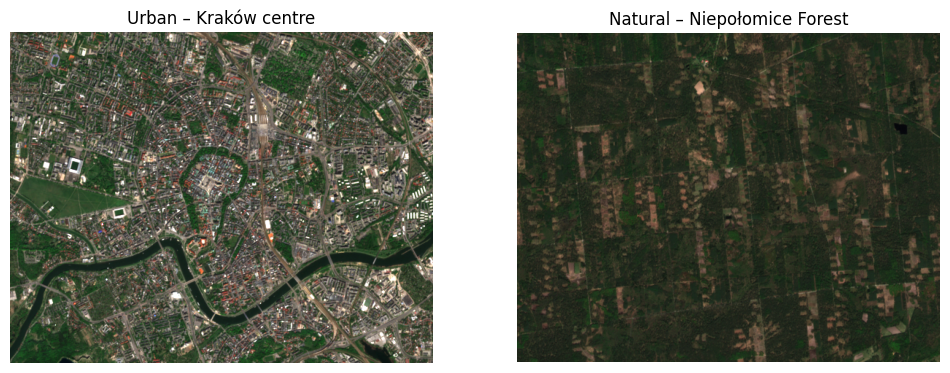

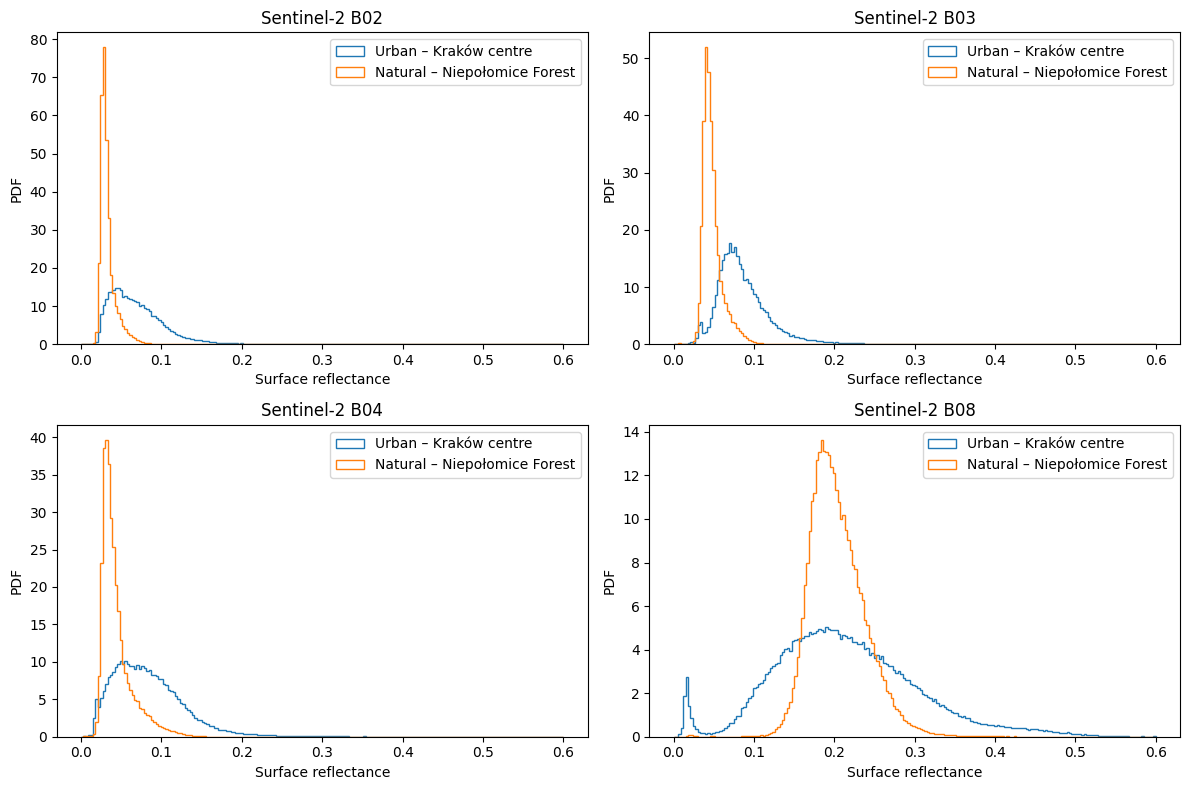

In [4]:
# Quick look – true colour composites
fig, ax = mp.subplots(1, 2, figsize=(12, 5))
for a, (name, d) in zip(ax, s2.items()):
    rgb = np.dstack([d["B04"], d["B03"], d["B02"]])
    a.imshow(np.clip(rgb / 0.25, 0, 1)); a.set_title(name); a.axis("off")
mp.show()

# PDF
fig, ax = mp.subplots(2, 2, figsize=(12, 8))
for a, b in zip(ax.ravel(), S2_BANDS):
    for name, d in s2.items():
        v = d[b][~np.isnan(d[b])]
        a.hist(v, bins=200, range=(0, 0.6), density=True, histtype="step", lw=1.5, label=name)
    a.set_title(f"Sentinel-2 {b}"); a.set_xlabel("Surface reflectance"); a.set_ylabel("PDF")
    a.legend()
mp.tight_layout(); mp.show()

## 1.3 Note your observations
**Visible bands**
- The forest Probability Distribution Function is a single, very narrow peak at low
  reflectance (around 0.03). That is because chlorophyll strongly absorbs blue and red
  light, and the canopy is spectrally homogeneous, so almost all pixels have similar values.
- The urban PDF is much broader, shifted to higher surface reflectance values and strongly
  right-skewed, with a long tail.

**Near-infrared**
- In NIR the forest reflectance jumps to around 0.19 (compared to ~0.03 in visible bands),
  as healthy leaves strongly reflect near-infrared light.
- Both areas now peak at similar surface-reflectance values. Both distributions are wider
  and have lower PDF values than in the visible bands, but the forest is still much narrower.
- The urban distribution is very wide and has a separate sharp peak near 0.02, which
  corresponds to the Vistula river, as water absorbs NIR almost completely.


>In the visible bands the PDFs of the two classes
  separate urban and natural areas quite well. In NIR the PDFs overlap strongly, so NIR on its
  own is a weak feature.

## 1.4 Repeat it for data from Sentinel 1 from the same regions

S1C_IW_GRDH_1SDV_20260928T162603_20260928T162628_009650_013357_rtc ascending


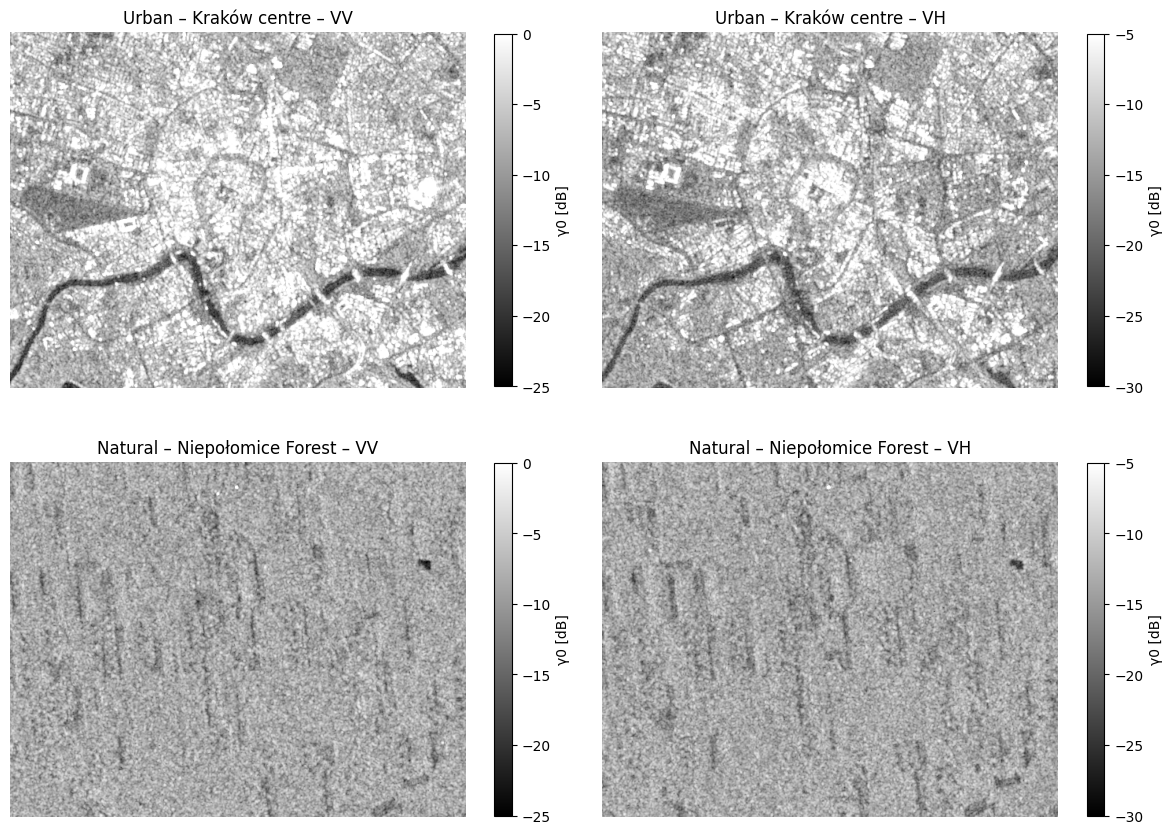

In [5]:
s1_item = pick_item("sentinel-1-rtc", "2026-05-01/2026-09-30")
print(s1_item.id, s1_item.properties.get("sat:orbit_state"))

s1 = {}
for name, bb in regions.items():
    ds = odc.stac.load([s1_item], bands=["vv", "vh"], bbox=bb, resolution=10).isel(time=0)
    s1[name] = {p: np.where(ds[p].values > 0, ds[p].values, np.nan) for p in ["vv", "vh"]}

# Quick look – Sentinel-1 backscatter in dB
fig, ax = mp.subplots(2, 2, figsize=(12, 9))
limits = {"vv": (-25, 0), "vh": (-30, -5)}
for i, (name, d) in enumerate(s1.items()):
    for j, p in enumerate(["vv", "vh"]):
        im = ax[i, j].imshow(10*np.log10(d[p]), cmap="gray", vmin=limits[p][0], vmax=limits[p][1])
        ax[i, j].set_title(f"{name} – {p.upper()}"); ax[i, j].axis("off")
        fig.colorbar(im, ax=ax[i, j], label="γ0 [dB]", shrink=0.8)
mp.tight_layout(); mp.show()

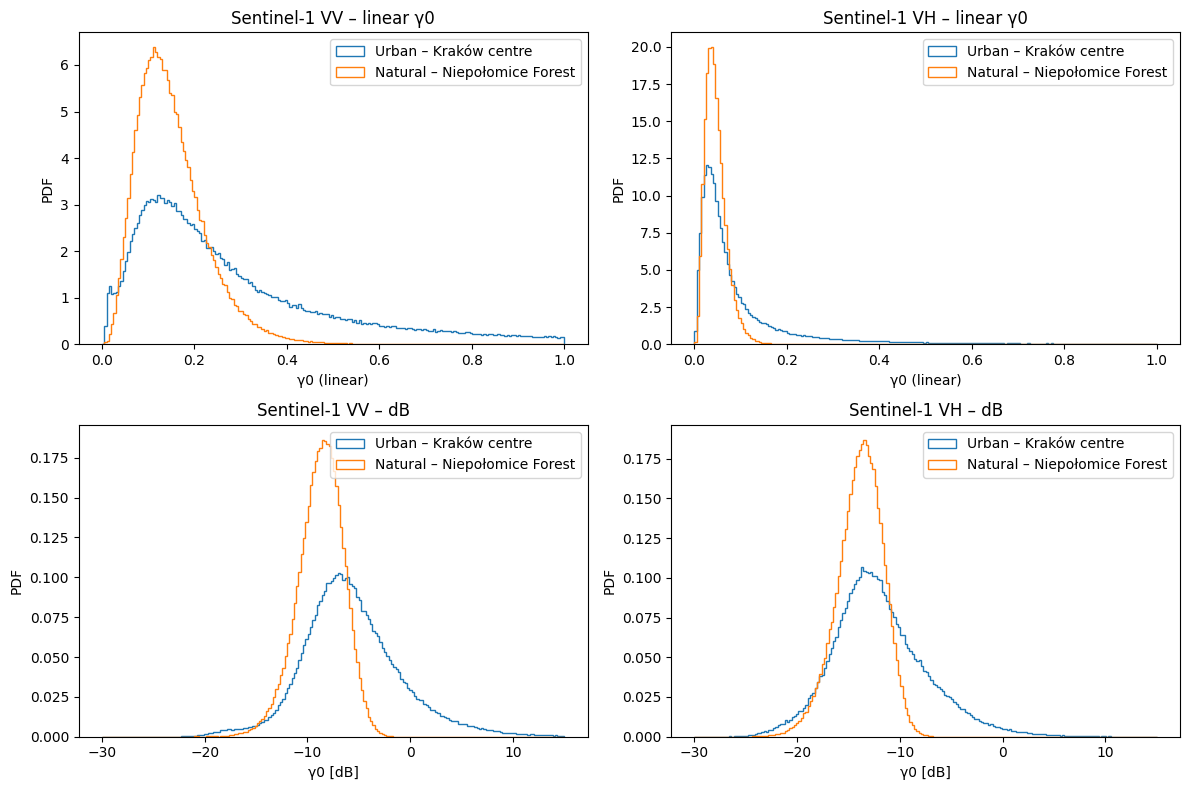

In [6]:
fig, ax = mp.subplots(2, 2, figsize=(12, 8))
for j, p in enumerate(["vv", "vh"]):
    for name, d in s1.items():
        v = d[p][~np.isnan(d[p])]
        ax[0, j].hist(v, bins=200, range=(0, 1), density=True, histtype="step", lw=1.5, label=name)
        ax[1, j].hist(10*np.log10(v), bins=200, range=(-30, 15), density=True, histtype="step", lw=1.5, label=name)
    ax[0, j].set_title(f"Sentinel-1 {p.upper()} – linear γ0"); ax[0, j].set_xlabel("γ0 (linear)")
    ax[1, j].set_title(f"Sentinel-1 {p.upper()} – dB");          ax[1, j].set_xlabel("γ0 [dB]")
    for a in ax[:, j]: a.set_ylabel("PDF"); a.legend()
mp.tight_layout(); mp.show()

**Linear scale**
- Both distributions are strongly right-skewed with a long tail. This is typical for SAR
  and comes from speckle.
- The forest PDF is again narrow and concentrated, while the urban one is much wider.
- Both distribution peak at similar y0 values.

**Decibel scale**
- After converting to dB the distributions become much more symmetric. That is because the logarithm turns the multiplicative speckle into an additive one.
- The forest gives a narrow, almost Gaussian peak.
- The urban PDF peaks at similar values, but it is much broader and right-skewed, with bright pixels up to +10 dB. They come from double-bounce scattering.


>Within each plot, the forest peak is higher than the urban one, but the ratio is much
  smaller for Sentinel-1 than for Sentinel-2.
This means that urban and natural areas are less separable in Sentinel-1, when only pixel values are used. The main reason is speckle, which can be filtered before classification.

# 2. Stegenography

## 2.1 Take any of the images you have worked on for the last question. Replace the last two LSB of each pixel with a randomly generated number.

**Check if it affects the visual quality of the image.**

For this exercise the Sentinel-2 red band of the urban area was used. It was first
converted to an 8-bit image, as this is the standard representation for displaying images and for classic LSB steganography.

In [7]:
band = s2["Urban – Kraków centre"]["B04"]
lo, hi = np.nanpercentile(band, [2, 98])
img8 = (np.clip((band - lo) / (hi - lo), 0, 1) * 255).astype(np.uint8)

rng = np.random.default_rng(42)
noise = rng.integers(0, 4, size=img8.shape, dtype=np.uint8)   # random 2-bit number per pixel
stego = (img8 & 0b11111100) | noise    # clears 2 LSBs, inserts random bits

print("Example pixel values (original):   ", img8[100, 100:108])
print("Example pixel values (manipulated):", stego[100, 100:108])

Example pixel values (original):    [190 173 118  51  58  68  90 131]
Example pixel values (manipulated): [188 173 119  50  56  68  90 128]


Max |difference| = 3 grey levels,  MSE = 2.54,  PSNR = 44.1 dB


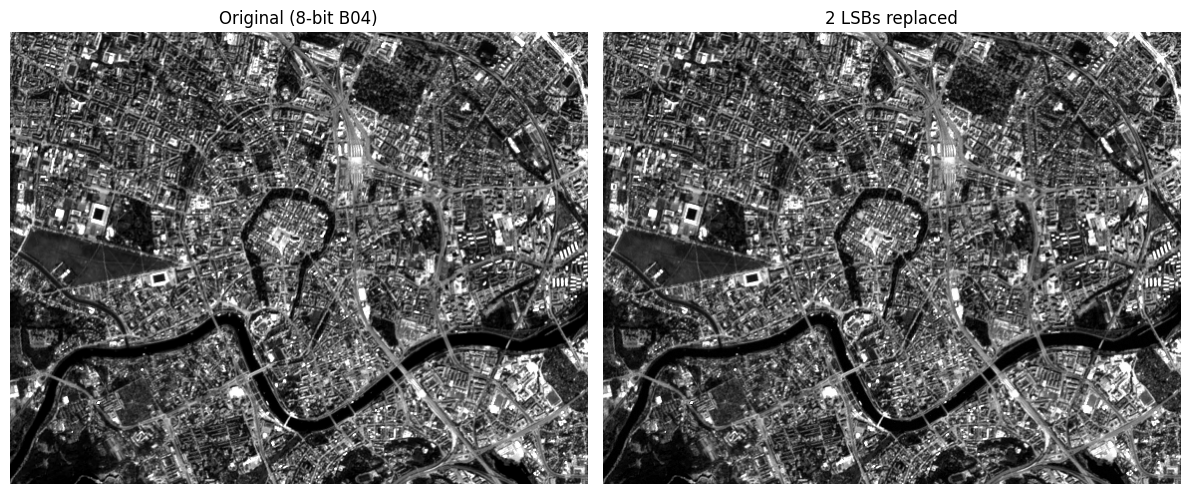

In [8]:
diff = img8.astype(int) - stego.astype(int)
mse = np.mean(diff**2)
psnr = 10 * np.log10(255**2 / mse)
print(f"Max |difference| = {np.abs(diff).max()} grey levels,  MSE = {mse:.2f},  PSNR = {psnr:.1f} dB")

fig, ax = mp.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(img8, cmap="gray");  ax[0].set_title("Original (8-bit B04)")
ax[1].imshow(stego, cmap="gray"); ax[1].set_title("2 LSBs replaced")
for a in ax: a.axis("off")
mp.tight_layout(); mp.show()

Replacing the two least significant bits does not affect the visual quality of the image.
Each pixel changes by at most 3 grey levels out of 256 and the original
and manipulated images look identical.

## 2.2  Plot the PDF of the original and manipulated images.


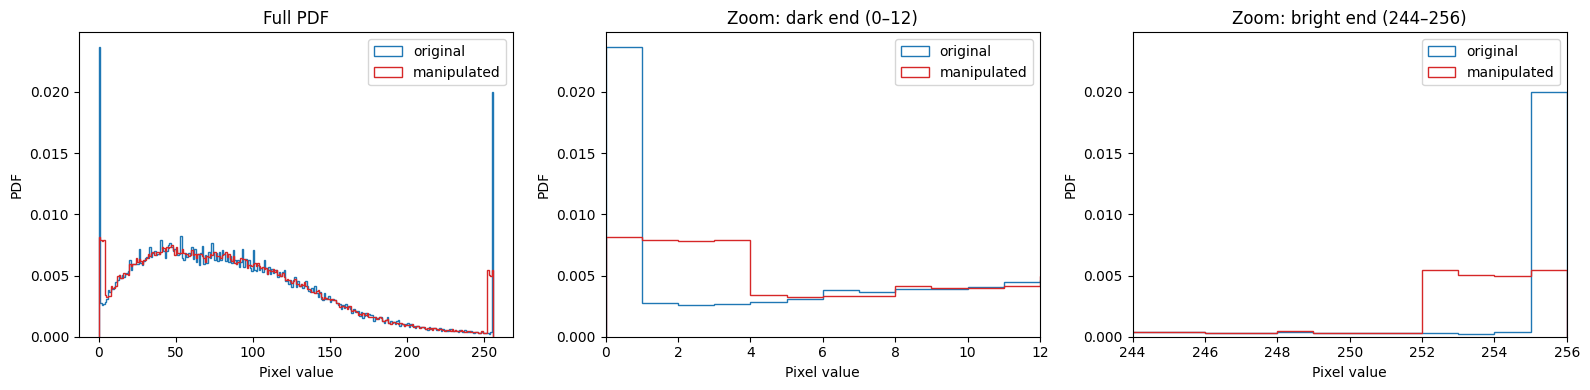

In [9]:
kw = dict(bins=256, range=(0, 256), density=True, histtype="step", lw=1.2)
fig, ax = mp.subplots(1, 3, figsize=(16, 4))
for a in ax:
    a.hist(img8.ravel(),  label="original",    color="tab:blue", **kw)
    a.hist(stego.ravel(), label="manipulated", color="tab:red",  **kw)
    a.set_xlabel("Pixel value"); a.set_ylabel("PDF"); a.legend()
ax[0].set_title("Full PDF")
ax[1].set_xlim(0, 12);    ax[1].set_title("Zoom: dark end (0–12)")
ax[2].set_xlim(244, 256); ax[2].set_title("Zoom: bright end (244–256)")
mp.tight_layout(); mp.show()

**Do you see any difference?**

The full PDFs of the original and manipulated images almost perfectly overlap. The only
clear difference is at both ends of the histogram. The original image has sharp peaks at
0 and 255 (clipped pixels). After replacing the 2 LSBs these peaks
are spread evenly over the values.

The differences found above appear only at the saturation peaks created by the contrast
stretch. To check whether the manipulation can be detected without them, the same
procedure was repeated on an image scaled linearly between its minimum and maximum
value .


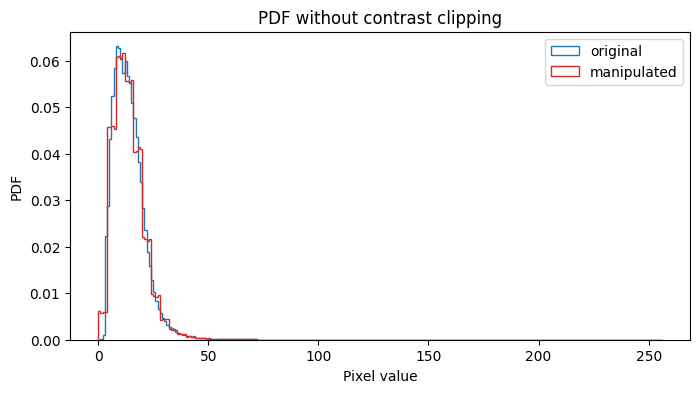

In [10]:
img8_mm = ((band - np.nanmin(band)) / (np.nanmax(band) - np.nanmin(band)) * 255).astype(np.uint8)
stego_mm = (img8_mm & 0b11111100) | rng.integers(0, 4, size=img8_mm.shape, dtype=np.uint8)

fig, ax = mp.subplots(figsize=(8, 4))
ax.hist(img8_mm.ravel(),  label="original",    color="tab:blue", **kw)
ax.hist(stego_mm.ravel(), label="manipulated", color="tab:red",  **kw)
ax.set_title("PDF without contrast clipping"); ax.set_xlabel("Pixel value"); ax.set_ylabel("PDF"); ax.legend()
mp.show()

For the image scaled without clipping (min–max) there is no visible difference between
the two PDFs.

**Can this be used to detect if a satellite image has been manipulated?**

Only in some cases. Here the manipulation was visible only because the original histogram
had peaks at 0 and 255. When the histogram is smooth, a change of ±3 grey levels looks
the same as normal sensor noise, so the PDF alone cannot show that the image was changed.

# 3. Run the compressive sensing code and note where it may be useful in EO

##Basic Optimization

In this page we shall demosntrate how to use Scipy's optimization package.


Lets optimize $f(x) = \exp{(x-2)^2}$

In [11]:
!pip install scikit-optimize

In [12]:
import numpy as np
import matplotlib.pyplot as mp
import scipy as sp
from scipy import optimize
from scipy import fftpack
import skopt as opt

def f(y):
    return -np.exp(-(y-2)**2)

result = optimize.minimize_scalar(f)

print(result)

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: -1.0
       x: 1.9999999955459995
     nit: 6
    nfev: 10



###Using minimize function
We can also use Python's minimize or maximize function (with the ''key'' option) to optimize the function!

You can also pass more arguments.

**Why to use the "optimize" function then?**
>Because it finds the minimum more precisely and with fewer function evaluations.

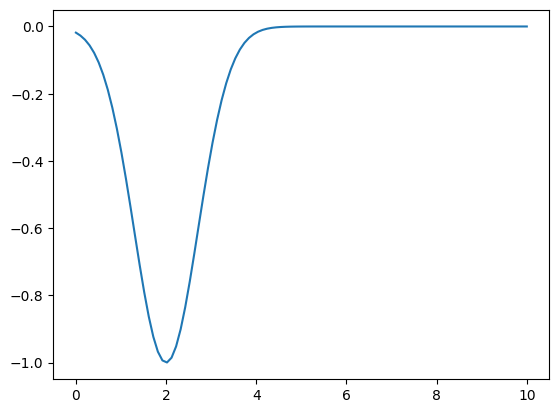

2.0202020202020203


In [13]:
y = np.linspace(0,10,100)
mp.plot(y,-np.exp(-(y-2)**2)); mp.show()
#print(max(y, key=lambda x: np.sinc(x-5)))

print(min(y, key=lambda x: -np.exp(-(x-2)**2)))

###Rosenbrock function

Now we optimize the infamous Rosenbrock function.

$f(x,y) = 0.5*(1-x)^2 + (y - x^2)^2$

In [14]:
def f(x):   # The rosenbrock function
    return .5*(1 - x[0])**2 + (x[1] - x[0]**2)**2
optimize.minimize(f, [0,-1], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 1.2743806081839638e-11
       x: [ 1.000e+00  1.000e+00]
     nit: 8
     jac: [-2.100e-07  2.518e-06]
    nfev: 48
    njev: 16

**What happens if we change the seed to something very far from the solution point?**
>The optimizer still finds the correct minimum, but it needs more iterations and function evaluations.

In [15]:
optimize.minimize(f, [200,-110], method="CG")

 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2.988484547652788e-10
       x: [ 1.000e+00  1.000e+00]
     nit: 19
     jac: [ 6.786e-06  8.505e-06]
    nfev: 158
    njev: 52

**Constrained Optimization**

In this you need to give the constraints as well.

For example: $f(x) = 2xy + 2x - x^2 - 2 y^2$.

Constraints are as follows:

$x^3−y = 0$

$y−1 \geq 0$

In [16]:
def func(x, sign=1.0):
    """ Objective function """
    return sign*(2*x[0]*x[1] + 2*x[0] - x[0]**2 - 2*x[1]**2)

cons = ({'type': 'eq',
          'fun' : lambda x: np.array([x[0]**3 - x[1]])},
        {'type': 'ineq',
          'fun' : lambda x: np.array([x[1] - 1])})

res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.999999999999997
            Iterations: 4
            Function evaluations: 13
            Gradient evaluations: 4
[1.99999994 0.99999995]


In [17]:
res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),
                constraints=cons, method='BFGS', options={'disp': True})

print(res.x)

Optimization terminated successfully.
         Current function value: -2.000000
         Iterations: 6
         Function evaluations: 21
         Gradient evaluations: 7
[2.00000009 1.00000005]


/tmp/ipykernel_80411/2128810766.py:1: RuntimeWarning: Method BFGS cannot handle constraints.
  res = optimize.minimize(func, [-1.0,1.0], args=(-1.0,),


In [18]:
#SLSQP with the constraints, cause the BFGS didn't pass
res = optimize.minimize(func, [-1.0, 1.0], args=(-1.0,), constraints=cons,
                        method='SLSQP', options={'disp': True})
print(res.x)

Optimization terminated successfully    (Exit mode 0)
            Current function value: -1.0000001831248642
            Iterations: 9
            Function evaluations: 32
            Gradient evaluations: 9
[1.00000009 1.        ]


## COMPRESSIVE SENSING

Now lets discuss about compressive sensing. Lets assume that we have some signal recorded (following Nyquist rate); lets call it $x$. Its size is $N$.

In the following signal we are using 500 samples and two sinusoids. You can note that one of them takes 10 samples per cycle; hence there are 50 cycles. So Nyquist will want us to have at least 100 samples in order to be able to know whats in the signal!

However if we look the signal through DCT then there are just two samples. Mark that we are using DCT and not FFT; because then we dont have to deal with complex numbers!



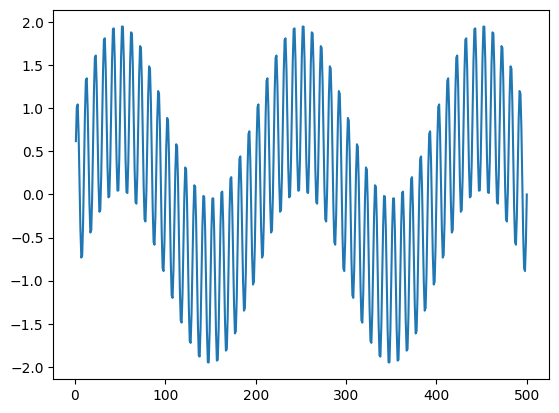

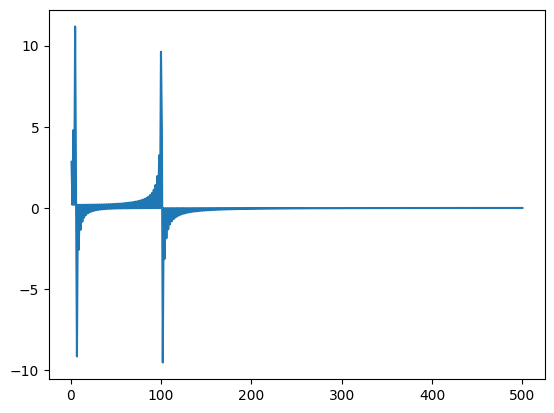

([<matplotlib.lines.Line2D at 0x7cf92133a490>], None)

In [19]:
n = np.linspace(1,500,500)

#two harmonics signal
xx = np.sin(2*np.pi*n/10) + np.sin(2*np.pi*n/200)  #+ np.sin(2*np.pi*n/50)
mp.plot(n,xx), mp.show()
mp.plot(n,fftpack.dct(xx, norm='ortho')), mp.show()

**Sparse Sampling** \\
Lets assume that we only consider $n$ of this ($n \ll N$).

For this lets define a sparsifying vector sp which has only $n$ 1's and rest zeros placed in random places.

So sparsed data $xp = xx*sp$.

The trick is that these $n$ samples are randomly taken.

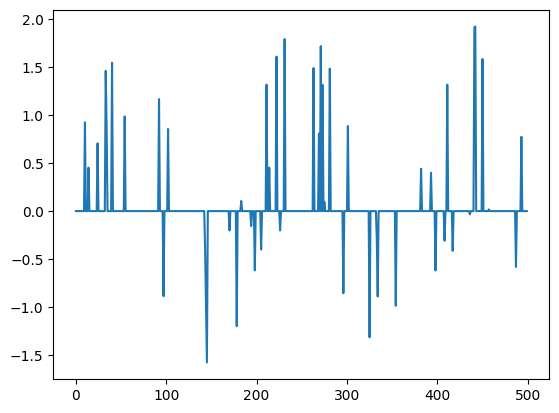

([<matplotlib.lines.Line2D at 0x7cf9234c7b10>], None)

In [20]:
N = len(xx) #length of actual N
n = 50 #number of nonzero samples in our sparse signal
sp = np.array([1] * n + [0] * (N-n)) #n 1's and (N-n) 0's
np.random.shuffle(sp)

xp = xx*sp
mp.plot(xp), mp.show()

### Using Optimization
The trick of compressive sensing is that we try to use optimization in order to know the unknown from what is known!

So let us think what we know.

1- We know $xp$  the random-subNyquist-sampled signal and $sp$.

2- We know that the signal is sparse in DCT domain.

So lets try to look into the DCT domain. Lets assume that the DCT of the signal is $XX$. So IDCT of it should give us $xp$ back.

Lets define an optimization problem to do this.

What are the DCT samples that will give rise to a time domain signal which has the values of $xp$ at $sp$ time-indices. \\
We start with an intial estimate $XX$ which we will update in each iteration. \\
The cost function will be Euclidean distance between $xp$ and IDCT of $XX$.

/usr/local/lib/python3.13/dist-packages/scipy/optimize/_minimize.py:779: OptimizeWarning: Desired error not necessarily achieved due to precision loss.
  res = _minimize_bfgs(fun, x0, args, jac, callback, **options)


         Current function value: 0.000000
         Iterations: 9
         Function evaluations: 64140
         Gradient evaluations: 128


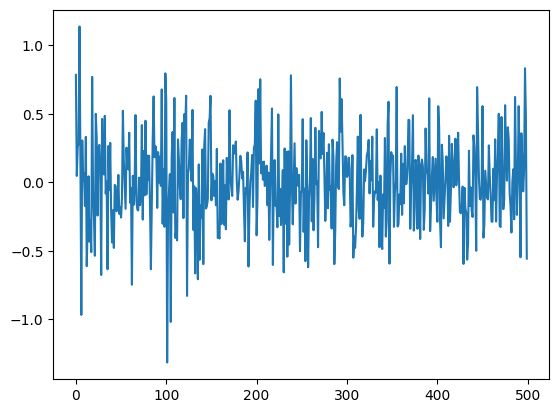

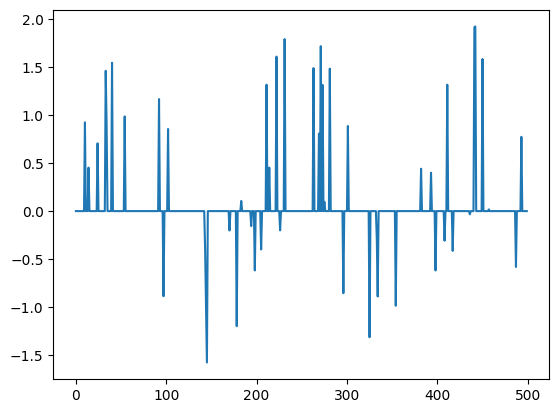

([<matplotlib.lines.Line2D at 0x7cf9213bbed0>], None)

In [21]:

XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Redfining the Optimization
Hmmmm. Enen though the optimization has not finished doing its job if we look at the result we seem to have achieved what we asked for!

The reconstructed signal $xrecon$ looks exactly like $xp$. So we did achieve what we wanted (theoritically speaking) but we want more.

What else can we do?

Lets add a condition that we want to optimize $||xrecon - xp ||$ but we also want to keep XX sparse, i.e. the $L0$ norm of $XX$ should be less than $n$.

Iteration limit reached    (Exit mode 9)
            Current function value: 2.122777238976646e-05
            Iterations: 100
            Function evaluations: 51377
            Gradient evaluations: 101


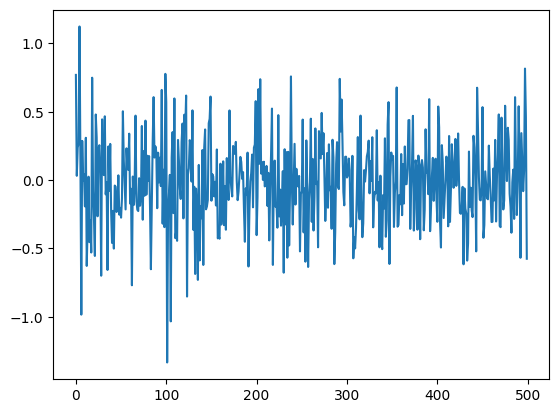

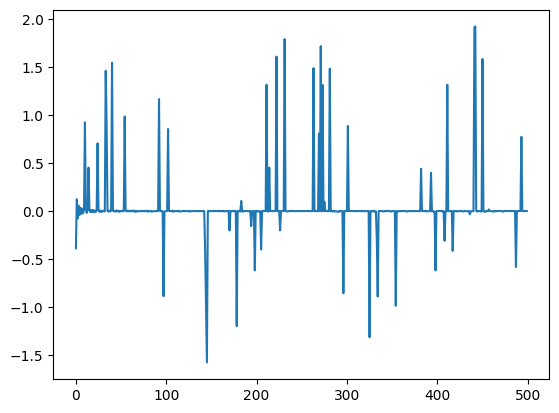

([<matplotlib.lines.Line2D at 0x7cf9210e02d0>], None)

In [22]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    xd = fftpack.idct(XX, norm='ortho') #derived x from X
    xdn = xd*sp
    return np.linalg.norm((xdn - xp), ord=2)

cons = ({'type': 'ineq',
          'fun' : lambda XX: n - np.linalg.norm(XX,ord=0)})

#seed = np.random.rand(N)
seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Re-redfining the Optimization: L1 Magic!!
Hmmmm. It seems its not working the way we want it to work. What else can we do?

It seems achieving $xrecon = xp$ is an easy task, because its sparse anyway.

So lets keep this as a condition (instead of making it the cost-function). And minimize $XX$. And let us use $L1$ norm here so as to keep the error under control. Remember that even though $L2$ norm is smooth, it has a square and blows up the error. So in wildly uknown problems like what we dealing with here, its better to use $L1$ norm.

In [23]:
XX = np.random.rand(N)
def cost_cs(XX):   #given the measured xp and a generic X find the L1 norm
    return np.linalg.norm(XX, ord=1)

cons = ({'type': 'eq',
          'fun' : lambda XX : np.linalg.norm(xp - fftpack.idct(XX, norm='ortho')*sp, ord = 2)})

seed = np.random.rand(N)
#seed = np.zeros(N)

CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})

Iteration limit reached    (Exit mode 9)
            Current function value: 62.35496250649862
            Iterations: 100
            Function evaluations: 50912
            Gradient evaluations: 101


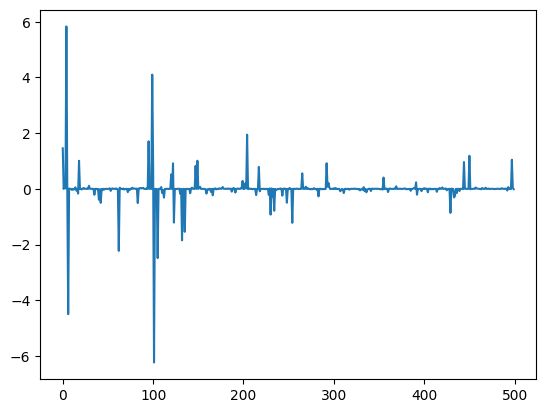

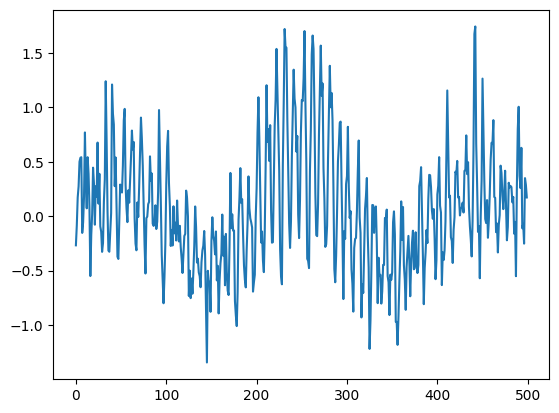

([<matplotlib.lines.Line2D at 0x7cf92136a850>], None)

In [24]:
xrecon = fftpack.idct(CS.x, norm='ortho')
mp.plot(CS.x), mp.show()
mp.plot(xrecon), mp.show()

### Conclusion
Unfortunately the optimization process did not end. We need more iteration. However, we seem to have got something which looks pretty much like the signal we have started with. It is noisy but it is encouraging given the fact that we have got only half the number of samples as Nyquist would have wanted.

This is the starting of Compressive Sensing (CS). We have learnt two things.

1- It is easy to cheat Nyquist if the signal is sparse in some other linearly transferable domain. 2- Redefining the optimization problem can help us achieve magical results.

The hard-core CS involvs more interesting objective functions and constraints to achieve even more interesting magical results.

##Where can compressive sensing be useful in EO?

Compressive sensing allows a signal to be reconstructed from fewer measurements than the
Nyquist rate requires, if the signal is sparse in some domain. In Earth observation this
can be useful for:

- **Reducing the amount of data** – satellites collect more data than they can send to
  Earth, so measuring or transmitting fewer samples saves storage
- **SAR imaging** – radar scenes often contain only a few strong scatterers, so they can
  be reconstructed from fewer samples.
- **Hyperspectral imaging**
- **Filling gaps in data** – reconstructing missing pixels.